# **Movie Dataset Python Assignment**


### **Question 1**
Dataset (`movie.csv`) ko pandas mein load karein aur uske pehle 5 rows display karein.

In [6]:
import pandas as pd
import numpy as np
data = pd.read_csv("movie.csv")
data.head()

,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Meta_score,Director,Star1,No_of_Votes,Gross
0,The Shawshank Redemption,1994,A,142 min,Drama,9.3,80.0,Frank Darabont,Tim Robbins,2343110,28341469.0
1,The Godfather,1972,A,175 min,"Crime, Drama",9.2,100.0,Francis Ford Coppola,Marlon Brando,1620367,134966411.0
2,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,84.0,Christopher Nolan,Christian Bale,2303232,534858444.0
3,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,90.0,Francis Ford Coppola,Al Pacino,1129952,57300000.0
4,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,96.0,Sidney Lumet,Henry Fonda,689845,4360000.0


### **Question 2**
Dataset ka total shape (rows aur columns count) check karke print karein.

In [2]:
import csv

with open("movie.csv", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)          # pehli row = column names
    rows = sum(1 for _ in reader)  # baaki rows count

print(f"Shape: ({rows}, {len(header)})")

Shape: (1000, 11)


### **Question 3**
Check karein ki kis kis column mein missing values (null values) hain aur unka exact count kya hai.

In [3]:
import csv

with open("movie.csv", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)
    missing = [0] * len(header)
    for row in reader:
        for i in range(len(header)):
            if i >= len(row) or row[i].strip().lower() in ("", "na", "nan", "null"):
                missing[i] += 1

for col, n in zip(header, missing):
    if n:
        print(col, n)
        

Certificate 101
Meta_score 157
Gross 169


### **Question 4**
Which movies were released after the year 2000? (Year 2000 ke baad release hone wali movies filter karein).

In [4]:
import csv

with open("movie.csv", newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        year = row["Released_Year"].strip()
        if year.isdigit() and int(year) > 2000:
            print(row["Series_Title"], year)

The Dark Knight 2008
The Lord of the Rings: The Return of the King 2003
Inception 2010
The Lord of the Rings: The Fellowship of the Ring 2001
The Lord of the Rings: The Two Towers 2002
Hamilton 2020
Gisaengchung 2019
Soorarai Pottru 2020
Interstellar 2014
Cidade de Deus 2002
Sen to Chihiro no kamikakushi 2001
Joker 2019
Whiplash 2014
The Intouchables 2011
The Prestige 2006
The Departed 2006
The Pianist 2002
Capharnaüm 2018
Ayla: The Daughter of War 2017
Vikram Vedha 2017
Kimi no na wa. 2016
Dangal 2016
Spider-Man: Into the Spider-Verse 2018
Avengers: Endgame 2019
Avengers: Infinity War 2018
Coco 2017
Django Unchained 2012
The Dark Knight Rises 2012
3 Idiots 2009
Taare Zameen Par 2007
WALL·E 2008
The Lives of Others 2006
Oldeuboi 2003
1917 2019
Tumbbad 2018
Andhadhun 2018
Drishyam 2013
Jagten 2012
Jodaeiye Nader az Simin 2011
Incendies 2010
Miracle in cell NO.7 2019
Babam ve Oglum 2005
Inglourious Basterds 2009
Eternal Sunshine of the Spotless Mind 2004
Amélie 2001
Chhichhore 2019
Uri: 

### **Question 5**
Which movies have an IMDB rating greater than 9? (9 se zyada IMDB rating wali movies display karein).

In [8]:
import csv

with open("movie.csv", newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        try:
            if float(row["IMDB_Rating"]) > 9:
                print(row["Series_Title"], row["IMDB_Rating"])
        except ValueError:
            pass  # khali ya galat rating wali row skip

The Shawshank Redemption 9.3
The Godfather 9.2


### **Question 6**
How many movies are there for each genre? (Har genre ki total kitni movies hain, count nikalye).

In [9]:
import csv
from collections import Counter

with open("movie.csv", newline="", encoding="utf-8") as f:
    c = Counter(g.strip() for r in csv.DictReader(f) for g in r["Genre"].split(","))

print(c.most_common())

[('Drama', 724), ('Comedy', 233), ('Crime', 209), ('Adventure', 196), ('Action', 189), ('Thriller', 137), ('Romance', 125), ('Biography', 109), ('Mystery', 99), ('Animation', 82), ('Sci-Fi', 67), ('Fantasy', 66), ('History', 56), ('Family', 56), ('War', 51), ('Music', 35), ('Horror', 32), ('Western', 20), ('Film-Noir', 19), ('Sport', 19), ('Musical', 17)]


### **Question 7**
Which movies were directed by Christopher Nolan? (Christopher Nolan ki directed saari movies nikalye).

In [10]:
import csv

with open("movie.csv", newline="", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        if r["Director"].strip() == "Christopher Nolan":
            print(r["Series_Title"], r["Released_Year"])

The Dark Knight 2008
Inception 2010
Interstellar 2014
The Prestige 2006
The Dark Knight Rises 2012
Memento 2000
Batman Begins 2005
Dunkirk 2017


### **Question 8**
Which movies have 'Drama' mentioned in their genre? ('Drama' genre wali movies ko filter karein).

In [12]:
import csv
with open("movie.csv", newline="", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        if "Drama" in [g.strip() for g in r["Genre"].split(",")]:
            print(r["Series_Title"], "|", r["Genre"])

The Shawshank Redemption | Drama
The Godfather | Crime, Drama
The Dark Knight | Action, Crime, Drama
The Godfather: Part II | Crime, Drama
12 Angry Men | Crime, Drama
The Lord of the Rings: The Return of the King | Action, Adventure, Drama
Pulp Fiction | Crime, Drama
Schindler's List | Biography, Drama, History
Fight Club | Drama
The Lord of the Rings: The Fellowship of the Ring | Action, Adventure, Drama
Forrest Gump | Drama, Romance
The Lord of the Rings: The Two Towers | Action, Adventure, Drama
Goodfellas | Biography, Crime, Drama
One Flew Over the Cuckoo's Nest | Drama
Hamilton | Biography, Drama, History
Gisaengchung | Comedy, Drama, Thriller
Soorarai Pottru | Drama
Interstellar | Adventure, Drama, Sci-Fi
Cidade de Deus | Crime, Drama
Saving Private Ryan | Drama, War
The Green Mile | Crime, Drama, Fantasy
La vita è bella | Comedy, Drama, Romance
Se7en | Crime, Drama, Mystery
The Silence of the Lambs | Crime, Drama, Thriller
Seppuku | Action, Drama, Mystery
Shichinin no samurai | 

### **Question 9**
How can we sort all movies by IMDB rating in descending order? (Movies ko highest se lowest rating ke mutabiq sort karein).

In [13]:
import csv
with open("movie.csv", newline="", encoding="utf-8") as f:
    rows = sorted((r for r in csv.DictReader(f) if r["IMDB_Rating"]), key=lambda r: float(r["IMDB_Rating"]), reverse=True)
for r in rows[:10]: print(r["Series_Title"], r["IMDB_Rating"])

The Shawshank Redemption 9.3
The Godfather 9.2
The Dark Knight 9
The Godfather: Part II 9
12 Angry Men 9
The Lord of the Rings: The Return of the King 8.9
Pulp Fiction 8.9
Schindler's List 8.9
Inception 8.8
Fight Club 8.8


### **Question 10**
How can we sort all movies by the number of votes they received? (No_of_Votes ke mutabiq descending order mein sort karein).

In [14]:
import csv
with open("movie.csv", newline="", encoding="utf-8") as f:
    rows = sorted((r for r in csv.DictReader(f) if r["No_of_Votes"]), key=lambda r: int(r["No_of_Votes"].replace(",", "")), reverse=True)
for r in rows[:10]: print(r["Series_Title"], r["No_of_Votes"])

The Shawshank Redemption 2343110
The Dark Knight 2303232
Inception 2067042
Fight Club 1854740
Pulp Fiction 1826188
Forrest Gump 1809221
The Matrix 1676426
The Lord of the Rings: The Fellowship of the Ring 1661481
The Lord of the Rings: The Return of the King 1642758
The Godfather 1620367


### **Question 11**
Which movie has the longest runtime? (Sabse lambi movie ka naam aur runtime minutes mein nikalye).

In [15]:
import csv
with open("movie.csv", newline="", encoding="utf-8") as f:
    rows = [r for r in csv.DictReader(f) if r["Runtime"]]
r = max(rows, key=lambda r: int(r["Runtime"].replace("min", "").strip()))
print(r["Series_Title"], r["Runtime"])

Gangs of Wasseypur 321 min


### **Question 12**
Which movies have Leonardo DiCaprio listed as the first star (Star1)?

In [16]:
import csv
with open("movie.csv", newline="", encoding="utf-8") as f:
    print([r["Series_Title"] for r in csv.DictReader(f) if r["Star1"] == "Leonardo DiCaprio"])

['Inception', 'The Departed', 'Shutter Island', 'The Wolf of Wall Street', 'Catch Me If You Can', 'The Revenant', 'Blood Diamond', 'Titanic', 'Once Upon a Time... in Hollywood']


### **Question 13**
What is the average IMDB rating of all movies? (Saari movies ki average rating calculate karein).

In [17]:
import csv
r=[float(x["IMDB_Rating"]) for x in csv.DictReader(open("movie.csv",encoding="utf-8")) if x["IMDB_Rating"]]
print(sum(r)/len(r))

7.9493


### **Question 14**
Dataset ka poora statistical summary (`describe()` function) display karein.

In [18]:
import csv, statistics as s
for c in ["IMDB_Rating","Meta_score","No_of_Votes","Gross"]:
    v=[float(r[c].replace(",","")) for r in csv.DictReader(open("movie.csv")) if r[c].strip()]
    print(c,len(v),s.mean(v),s.stdev(v),min(v),max(v))

IMDB_Rating 1000 7.9493 0.27549120749200945 7.6 9.3
Meta_score 843 77.97153024911032 12.376099328602027 28.0 100.0
No_of_Votes 1000 273692.911 327372.70393412496 25088.0 2343110.0
Gross 831 68034750.87364621 109750043.19218515 1305.0 936662225.0


### **Question 15**
'Runtime' column se 'min' text ko hata kar use proper integer (numeric) data type mein convert karein.

In [19]:
import csv
rows = list(csv.DictReader(open("movie.csv", encoding="utf-8")))
for r in rows: r["Runtime"] = int(r["Runtime"].replace(" min", "")) if r["Runtime"] else None

### **Question 16**
'Gross' column mein jo missing values (NaN) hain, unko pooray column ke median value se fill (impute) karein.

In [20]:
import csv, statistics as s
rows = list(csv.DictReader(open("movie.csv", encoding="utf-8")))
med = s.median(float(r["Gross"].replace(",", "")) for r in rows if r["Gross"].strip())
for r in rows: r["Gross"] = float(r["Gross"].replace(",", "")) if r["Gross"].strip() else med

### **Question 17**
Har 'Certificate' category mein total kitni movies hain? (Value counts nikalye).

In [21]:
import csv
from collections import Counter
print(Counter(r["Certificate"] or "Missing" for r in csv.DictReader(open("movie.csv", encoding="utf-8"))))

Counter({'U': 234, 'A': 197, 'UA': 175, 'R': 146, 'Missing': 101, 'PG-13': 43, 'PG': 37, 'Passed': 34, 'G': 12, 'Approved': 11, 'TV-PG': 3, 'GP': 2, 'TV-14': 1, '16': 1, 'TV-MA': 1, 'Unrated': 1, 'U/A': 1})


### **Question 18**
'IMDB_Rating' aur 'Meta_score' ke darmiyan correlation coefficient maloom karein.

In [24]:
import csv, statistics as s
p = [(float(r["IMDB_Rating"]), float(r["Meta_score"])) for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["IMDB_Rating"] and r["Meta_score"]]
print(s.correlation(*zip(*p)))

0.26853084455955467


### **Question 19**
Ek naya column banayein 'Rating_100_Scale' jisme 'IMDB_Rating' ko 10 se multiply kiya gaya ho.

In [28]:
import csv
rows = list(csv.DictReader(open("movie.csv", encoding="utf-8")))
for r in rows: r["Rating_100_Scale"] = round(float(r["IMDB_Rating"]) * 10, 1) if r["IMDB_Rating"] else None
print(rows[0]["Series_Title"], rows[0]["Rating_100_Scale"])

The Shawshank Redemption 93.0


### **Question 20**
Year 1990 se 2000 (both inclusive) ke darmiyan release hone wali movies ki total count aur list nikaleyin.

In [2]:
import csv
m = [r["Series_Title"] for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["Released_Year"].isdigit() and 1990 <= int(r["Released_Year"]) <= 2000]
print(len(m), m)

169 ['The Shawshank Redemption', 'Pulp Fiction', "Schindler's List", 'Fight Club', 'Forrest Gump', 'The Matrix', 'Goodfellas', 'Saving Private Ryan', 'The Green Mile', 'La vita è bella', 'Se7en', 'The Silence of the Lambs', 'Gladiator', 'American History X', 'The Usual Suspects', 'Léon', 'The Lion King', 'Terminator 2: Judgment Day', 'Memento', 'Mononoke-hime', 'Snatch', 'Requiem for a Dream', 'American Beauty', 'Good Will Hunting', 'Bacheha-Ye aseman', 'Toy Story', 'Braveheart', 'Reservoir Dogs', 'Hera Pheri', 'Lock, Stock and Two Smoking Barrels', 'L.A. Confidential', 'Eskiya', 'Heat', 'Casino', 'Andaz Apna Apna', 'Unforgiven', 'Amores perros', 'Shin seiki Evangelion Gekijô-ban: Air/Magokoro wo, kimi ni', 'The Sixth Sense', "La leggenda del pianista sull'oceano", 'The Truman Show', 'Crna macka, beli macor', 'The Big Lebowski', 'Fa yeung nin wah', 'Trainspotting', 'Fargo', 'Underground', 'La haine', 'Dilwale Dulhania Le Jayenge', 'Before Sunrise', 'Trois couleurs: Rouge', 'Chung Hing 

### **Question 21**
(Visualization) IMDB_Rating ka distribution dekhne ke liye ek neat Histogram plot karein.

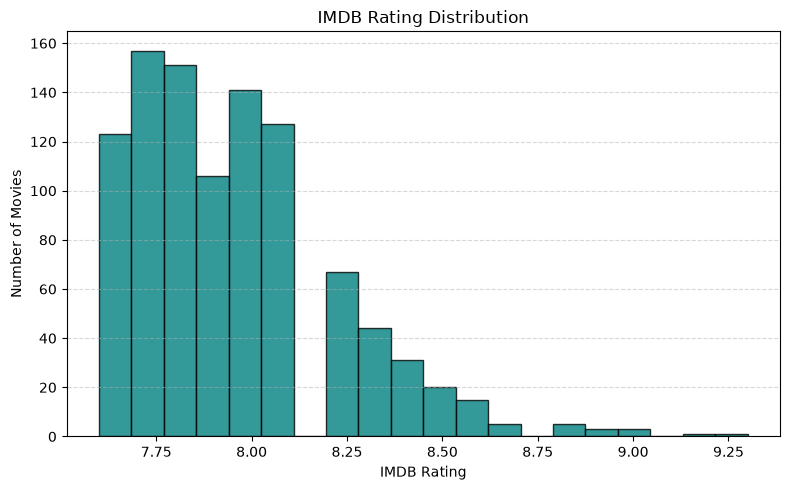

In [3]:
import csv
import matplotlib.pyplot as plt

r = [float(x["IMDB_Rating"]) for x in csv.DictReader(open("movie.csv", encoding="utf-8")) if x["IMDB_Rating"]]

plt.figure(figsize=(8, 5))
plt.hist(r, bins=20, color="teal", edgecolor="black", alpha=0.8)
plt.title("IMDB Rating Distribution")
plt.xlabel("IMDB Rating")
plt.ylabel("Number of Movies")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### **Question 22**
(Visualization) Top 10 Directors aur unki total movies ka ek attractive Bar Chart banayein.

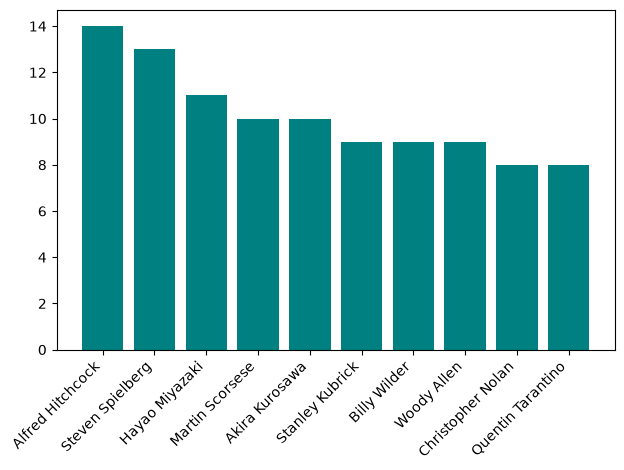

In [4]:
import csv
from collections import Counter
import matplotlib.pyplot as plt

d = Counter(r["Director"] for r in csv.DictReader(open("movie.csv", encoding="utf-8"))).most_common(10)
plt.bar(*zip(*d), color="teal")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### **Question 23**
(Visualization) IMDB_Rating aur Gross revenue ke darmiyan ek Scatter Plot banayein taake dono ka relation dikhe.

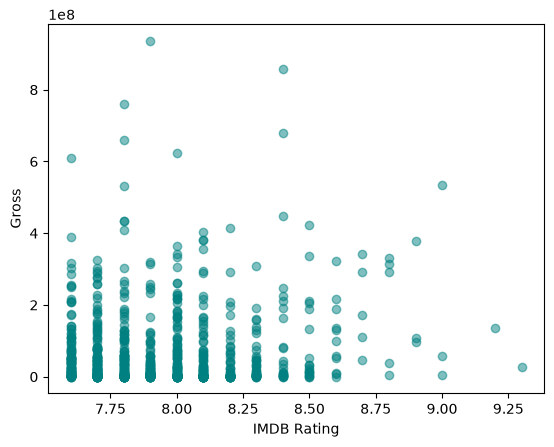

In [5]:
import csv
import matplotlib.pyplot as plt

p = [(float(r["IMDB_Rating"]), float(r["Gross"].replace(",", ""))) for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["IMDB_Rating"] and r["Gross"].strip()]
plt.scatter(*zip(*p), alpha=0.5, color="teal")
plt.xlabel("IMDB Rating")
plt.ylabel("Gross")
plt.show()

### **Question 24**
(Visualization) Genres ka count dekhne ke liye top 5 genres ka ek clean Pie Chart banayein.

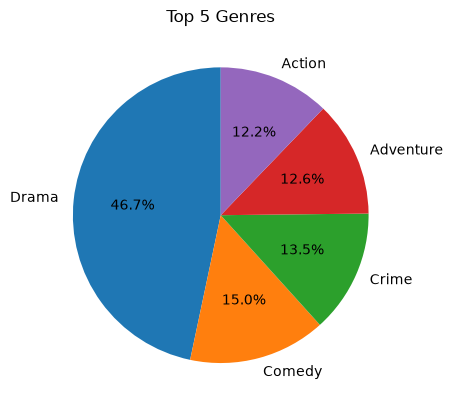

In [6]:
import csv
from collections import Counter
import matplotlib.pyplot as plt

g = Counter(x.strip() for r in csv.DictReader(open("movie.csv", encoding="utf-8")) for x in r["Genre"].split(",")).most_common(5)
plt.pie([n for _, n in g], labels=[k for k, _ in g], autopct="%1.1f%%", startangle=90)
plt.title("Top 5 Genres")
plt.show()

### **Question 25**
(Visualization) Meta_score ka distribution aur outliers check karne ke liye ek Box Plot banayein.

C:\Users\p\AppData\Local\Temp\ipykernel_14264\3254671426.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(m, vert=False)


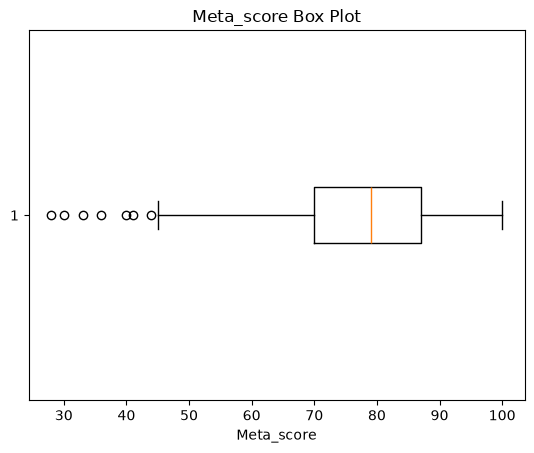

In [7]:
import csv
import matplotlib.pyplot as plt

m = [float(r["Meta_score"]) for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["Meta_score"].strip()]
plt.boxplot(m, vert=False)
plt.xlabel("Meta_score")
plt.title("Meta_score Box Plot")
plt.show()

### **Question 26**
(Visualization) Dataset mein 'Certificate' wise average 'Gross' kamai ka ek Bar Plot banayein.

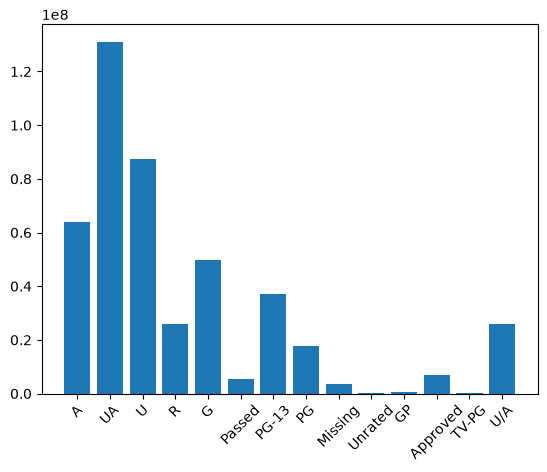

In [8]:
import csv
import matplotlib.pyplot as plt

d = {}
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["Gross"].strip(): d.setdefault(r["Certificate"] or "Missing", []).append(float(r["Gross"].replace(",", "")))
plt.bar(d.keys(), [sum(v)/len(v) for v in d.values()])
plt.xticks(rotation=45)
plt.show()

### **Question 27**
(Visualization) Har saal (Released_Year) kitni movies release hueen, iska ek Line Plot banayein.

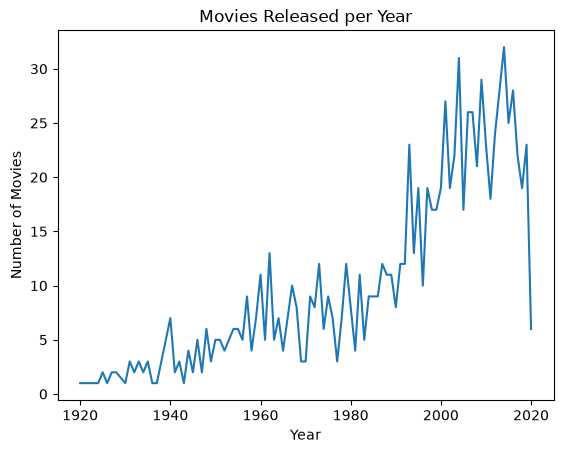

In [9]:
import csv
from collections import Counter
import matplotlib.pyplot as plt

y = sorted(Counter(int(r["Released_Year"]) for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["Released_Year"].isdigit()).items())
plt.plot(*zip(*y))
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.title("Movies Released per Year")
plt.show()

### **Question 28**
(Visualization) 'No_of_Votes' ke mutabiq top 5 highest voted movies ka ek Horizontal Bar Chart banayein.

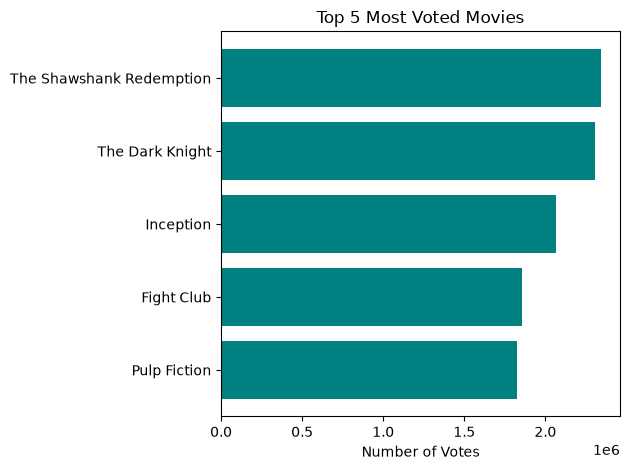

In [10]:
import csv
import matplotlib.pyplot as plt

t = sorted((r for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["No_of_Votes"].strip()), key=lambda r: int(r["No_of_Votes"].replace(",", "")), reverse=True)[:5]
plt.barh([r["Series_Title"] for r in t][::-1], [int(r["No_of_Votes"].replace(",", "")) for r in t][::-1], color="teal")
plt.xlabel("Number of Votes")
plt.title("Top 5 Most Voted Movies")
plt.tight_layout()
plt.show()

### **Question 29**
Har movie ke 'Genre' column ko split karke check karein ki total unique genres pure dataset mein kitne hain.

In [11]:
import csv
u = {g.strip() for r in csv.DictReader(open("movie.csv", encoding="utf-8")) for g in r["Genre"].split(",") if g.strip()}
print(len(u), sorted(u))

21 ['Action', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Drama', 'Family', 'Fantasy', 'Film-Noir', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Sport', 'Thriller', 'War', 'Western']


### **Question 30**
Dataset ko poora clean karne ke baad safely ek nayi csv file 'cleaned_movies.csv' ke naam se save karein.

In [12]:
import csv, statistics as s
rows = list(csv.DictReader(open("movie.csv", encoding="utf-8")))
med = s.median(float(r["Gross"].replace(",", "")) for r in rows if r["Gross"].strip())
for r in rows:
    r["Runtime"] = r["Runtime"].replace(" min", "")
    r["Gross"] = r["Gross"].replace(",", "") or med
w = csv.DictWriter(open("cleaned_movies.csv", "w", newline="", encoding="utf-8"), fieldnames=rows[0])
w.writeheader(); w.writerows(rows)

### **Question 31**
Kaunsi movies hain jinki 'IMDB_Rating' 8.5 se zyada hai AUR unka 'Gross' revenue 100 million (100,000,000) se zyada hai? (Dual condition filter)

In [13]:
import csv
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["IMDB_Rating"] and r["Gross"].strip() and float(r["IMDB_Rating"]) > 8.5 and float(r["Gross"].replace(",", "")) > 100000000:
        print(r["Series_Title"], r["IMDB_Rating"], r["Gross"])

The Godfather 9.2 134966411
The Dark Knight 9 534858444
The Lord of the Rings: The Return of the King 8.9 377845905
Pulp Fiction 8.9 107928762
Inception 8.8 292576195
The Lord of the Rings: The Fellowship of the Ring 8.8 315544750
Forrest Gump 8.8 330252182
The Lord of the Rings: The Two Towers 8.7 342551365
The Matrix 8.7 171479930
Star Wars: Episode V - The Empire Strikes Back 8.7 290475067
One Flew Over the Cuckoo's Nest 8.7 112000000
Interstellar 8.6 188020017
Saving Private Ryan 8.6 216540909
The Green Mile 8.6 136801374
Se7en 8.6 100125643
The Silence of the Lambs 8.6 130742922
Star Wars 8.6 322740140


### **Question 32**
Director 'Christopher Nolan' ki un movies ke naam aur release year nikalein jinka 'Runtime' 140 minutes se zyada hai.

In [14]:
import csv
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["Director"] == "Christopher Nolan" and r["Runtime"].strip() and int(r["Runtime"].replace(" min", "")) > 140:
        print(r["Series_Title"], r["Released_Year"])

The Dark Knight 2008
Inception 2010
Interstellar 2014
The Dark Knight Rises 2012


### **Question 33**
Aise actors (Star1) ki list nikalein jinhone 'Action' ya 'Sci-Fi' genre mein kaam kiya hai AUR unki movies ki 'IMDB_Rating' kam az kam 8.0 hai.

In [15]:
import csv
a = {r["Star1"] for r in csv.DictReader(open("movie.csv", encoding="utf-8"))
     if r["IMDB_Rating"] and float(r["IMDB_Rating"]) >= 8.0
     and {"Action", "Sci-Fi"} & {g.strip() for g in r["Genre"].split(",")}}
print(len(a), sorted(a))

72 ['Aamir Khan', 'Akshay Kumar', 'Alan Mak', 'Alisa Freyndlikh', 'Anupam Kher', 'Arnold Schwarzenegger', 'Atsuko Tanaka', 'Brigitte Helm', 'Bruce Willis', 'Buster Keaton', 'Cem Yilmaz', 'Charlton Heston', 'Choi Min-sik', 'Chris Pratt', 'Chris Sanders', 'Christian Bale', 'Clint Eastwood', 'Craig T. Nelson', 'Daniel Brühl', 'Daniel Craig', 'Donnie Yen', 'Eli Marienthal', 'Elijah Wood', 'Erdem Can', 'Harrison Ford', 'Hugh Jackman', 'Hugo Weaving', 'Iko Uwais', 'Irrfan Khan', 'Jake Gyllenhaal', 'James Cagney', 'Jang Dong-Gun', 'Jason Flemyng', 'Jean Reno', 'Jim Carrey', 'Joaquin Phoenix', 'Joe Russo', 'John Wayne', 'Johnny Depp', 'Kazuya Tsurumaki', 'Keir Dullea', 'Kurt Russell', 'Leonardo DiCaprio', 'Lilly Wachowski', 'Malcolm McDowell', 'Manoj Bajpayee', 'Mark Hamill', 'Matt Damon', 'Matthew McConaughey', 'Michael J. Fox', 'Mitsuo Iwata', 'Natalya Bondarchuk', 'Peter Ramsey', 'Prabhas', 'Pushkar', 'Robert Downey Jr.', 'Russell Crowe', 'Ryan Reynolds', 'Salman Khan', 'Sam Neill', 'Sanjee

### **Question 34**
Year 2010 se 2020 ke darmiyan release hone wali un movies ka data filter karein jinko Certificate 'UA' ya 'A' mila hai.

In [16]:
import csv
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["Released_Year"].isdigit() and 2010 <= int(r["Released_Year"]) <= 2020 and r["Certificate"] in ("UA", "A"):
        print(r["Series_Title"], r["Released_Year"], r["Certificate"])
        

Inception 2010 UA
Gisaengchung 2019 A
Interstellar 2014 UA
Joker 2019 A
Whiplash 2014 A
The Intouchables 2011 UA
Capharnaüm 2018 A
Vikram Vedha 2017 UA
Avengers: Endgame 2019 UA
Avengers: Infinity War 2018 UA
Django Unchained 2012 A
The Dark Knight Rises 2012 UA
Tumbbad 2018 A
Andhadhun 2018 UA
Chhichhore 2019 UA
Uri: The Surgical Strike 2018 UA
K.G.F: Chapter 1 2018 UA
Green Book 2018 UA
Three Billboards Outside Ebbing, Missouri 2017 A
Talvar 2015 UA
Baahubali 2: The Conclusion 2017 UA
Drishyam 2015 UA
Queen 2013 UA
Gangs of Wasseypur 2012 A
Udaan 2010 UA
Paan Singh Tomar 2012 UA
Warrior 2011 UA
Shutter Island 2010 A
The Wolf of Wall Street 2013 A
Pink 2016 UA
Ah-ga-ssi 2016 A
Haider 2014 UA
Logan 2017 A
PK 2014 UA
The Grand Budapest Hotel 2014 UA
Gone Girl 2014 A
Hacksaw Ridge 2016 A
12 Years a Slave 2013 A
Rush 2013 UA
Ford v Ferrari 2019 UA
Spotlight 2015 A
Kahaani 2012 UA
Prisoners 2013 A
Mad Max: Fury Road 2015 UA
Harry Potter and the Deathly Hallows: Part 2 2011 UA
Badhaai ho 20

### **Question 35**
Dataset mein 'Meta_score' 90 se zyada aur 'IMDB_Rating' 8.5 se kam wali unique movies kaunsi hain?

In [17]:
import csv
m = {r["Series_Title"] for r in csv.DictReader(open("movie.csv", encoding="utf-8"))
     if r["Meta_score"].strip() and r["IMDB_Rating"].strip()
     and float(r["Meta_score"]) > 90 and float(r["IMDB_Rating"]) < 8.5}
print(len(m), sorted(m))

117 ['12 Years a Slave', '4 luni, 3 saptamâni si 2 zile', '8½', "A Hard Day's Night", 'A Streetcar Named Desire', 'All About Eve', 'All Quiet on the Western Front', 'Amour', 'Anatomy of a Murder', 'Annie Hall', 'Apocalypse Now', 'Badlands', 'Beauty and the Beast', 'Before Midnight', 'Boyhood', 'Bride of Frankenstein', 'Brief Encounter', 'Bringing Up Baby', 'Bronenosets Potemkin', 'Call Me by Your Name', 'Chinatown', 'Citizen Kane', 'Cool Hand Luke', 'Days of Heaven', 'Do the Right Thing', 'Double Indemnity', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', 'Du rififi chez les hommes', 'Duck Soup', 'Dunkirk', 'E.T. the Extra-Terrestrial', 'Fanny och Alexander', 'Fantasia', 'Frankenstein', 'Gone with the Wind', 'Gravity', 'Il conformista', 'Inside Out', 'Invasion of the Body Snatchers', 'Jodaeiye Nader az Simin', 'Jules et Jim', 'La La Land', 'La battaglia di Algeri', 'La dolce vita', 'Lawrence of Arabia', 'Le charme discret de la bourgeoisie', 'Le scaphandre et le

### **Question 36**
(Visualization) 'Drama' aur 'Action' genres ki movies ke 'Gross' revenue ko compare karne ke liye ek Grouped Box Plot ya Violin Plot banayein.

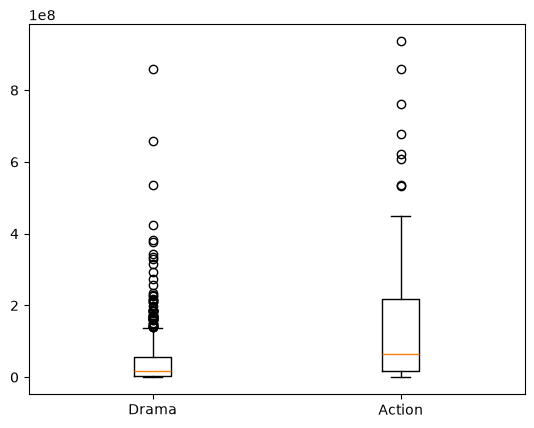

In [18]:
import csv
import matplotlib.pyplot as plt

d = {"Drama": [], "Action": []}
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["Gross"].strip():
        for g in r["Genre"].split(","):
            if g.strip() in d: d[g.strip()].append(float(r["Gross"].replace(",", "")))
plt.boxplot(d.values(), tick_labels=d.keys())
plt.show()


### **Question 37**
Har Director ki un movies ka count maloom karein jinhone 'No_of_Votes' 500,000 (5 lakh) se zyada hasil kiye hain.

In [19]:
import csv
from collections import Counter
c = Counter(r["Director"] for r in csv.DictReader(open("movie.csv", encoding="utf-8")) if r["No_of_Votes"].strip() and int(r["No_of_Votes"].replace(",", "")) > 500000)
print(c.most_common())

[('Christopher Nolan', 8), ('Quentin Tarantino', 8), ('Steven Spielberg', 8), ('Peter Jackson', 5), ('David Fincher', 5), ('Martin Scorsese', 5), ('James Cameron', 5), ('Ridley Scott', 4), ('Anthony Russo', 4), ('Stanley Kubrick', 4), ('Francis Ford Coppola', 3), ('Robert Zemeckis', 3), ('Guy Ritchie', 3), ('Pete Docter', 3), ('Matthew Vaughn', 3), ('Frank Darabont', 2), ('Todd Phillips', 2), ('Damien Chazelle', 2), ('Bryan Singer', 2), ('Andrew Stanton', 2), ('Darren Aronofsky', 2), ('Sam Mendes', 2), ('John Lasseter', 2), ('Terry Gilliam', 2), ('Denis Villeneuve', 2), ('Clint Eastwood', 2), ('Joel Coen', 2), ('Danny Boyle', 2), ('James Gunn', 2), ('Alejandro G. Iñárritu', 2), ('Brad Bird', 2), ('J.J. Abrams', 2), ('Doug Liman', 2), ('Alfonso Cuarón', 2), ('Zack Snyder', 2), ('Sidney Lumet', 1), ('Sergio Leone', 1), ('Lana Wachowski', 1), ('Irvin Kershner', 1), ('Milos Forman', 1), ('Bong Joon Ho', 1), ('Fernando Meirelles', 1), ('Hayao Miyazaki', 1), ('Roberto Benigni', 1), ('Jonatha

### **Question 38**
Un movies ke naam aur ratings batayein jinka 'Released_Year' 2000 se pehle ka hai AUR unka 'Gross' unke overall median gross se zyada hai.

In [20]:
import csv, statistics as s
rows = list(csv.DictReader(open("movie.csv", encoding="utf-8")))
med = s.median(float(r["Gross"].replace(",", "")) for r in rows if r["Gross"].strip())
for r in rows:
    if r["Released_Year"].isdigit() and int(r["Released_Year"]) < 2000 and r["Gross"].strip() and float(r["Gross"].replace(",", "")) > med:
        print(r["Series_Title"], r["IMDB_Rating"])

The Shawshank Redemption 9.3
The Godfather 9.2
The Godfather: Part II 9
Pulp Fiction 8.9
Schindler's List 8.9
Fight Club 8.8
Forrest Gump 8.8
The Matrix 8.7
Goodfellas 8.7
Star Wars: Episode V - The Empire Strikes Back 8.7
One Flew Over the Cuckoo's Nest 8.7
Saving Private Ryan 8.6
The Green Mile 8.6
La vita è bella 8.6
Se7en 8.6
The Silence of the Lambs 8.6
Star Wars 8.6
The Lion King 8.5
Terminator 2: Judgment Day 8.5
Back to the Future 8.5
Psycho 8.5
Raiders of the Lost Ark 8.4
The Shining 8.4
Apocalypse Now 8.4
Alien 8.4
Rear Window 8.4
American Beauty 8.3
Good Will Hunting 8.3
Toy Story 8.3
Braveheart 8.3
Full Metal Jacket 8.3
Aliens 8.3
Amadeus 8.3
Scarface 8.3
Star Wars: Episode VI - Return of the Jedi 8.3
Taxi Driver 8.3
The Sting 8.3
2001: A Space Odyssey 8.3
Lawrence of Arabia 8.3
L.A. Confidential 8.2
Heat 8.2
Casino 8.2
Unforgiven 8.2
Indiana Jones and the Last Crusade 8.2
Die Hard 8.2
Some Like It Hot 8.2
The Sixth Sense 8.1
The Truman Show 8.1
Fargo 8.1
Jurassic Park 8.1


### **Question 39**
Aisi movies ka data nikalein jahan 'Star1' (Main Actor) aur 'Director' dono bilkul same person hain.

In [21]:
import csv
for r in csv.DictReader(open("movie.csv", encoding="utf-8")):
    if r["Star1"].strip() and r["Star1"].strip() == r["Director"].strip():
        print(r["Series_Title"], r["Released_Year"], r["Director"])

La vita è bella 1997 Roberto Benigni
Modern Times 1936 Charles Chaplin
City Lights 1931 Charles Chaplin
The Great Dictator 1940 Charles Chaplin
Braveheart 1995 Mel Gibson
Citizen Kane 1941 Orson Welles
The Kid 1921 Charles Chaplin
Unforgiven 1992 Clint Eastwood
The Gold Rush 1925 Charles Chaplin
Sherlock Jr. 1924 Buster Keaton
Gran Torino 2008 Clint Eastwood
The Circus 1928 Charles Chaplin
Bom Yeoareum Gaeul Gyeoul Geurigo Bom 2003 Ki-duk Kim
Sling Blade 1996 Billy Bob Thornton
Dances with Wolves 1990 Kevin Costner
Annie Hall 1977 Woody Allen
This Is Spinal Tap 1984 Rob Reiner
Manhattan 1979 Woody Allen
La montaña sagrada 1973 Alejandro Jodorowsky
Hana-bi 1997 Takeshi Kitano
A Bronx Tale 1993 Robert De Niro
The Outlaw Josey Wales 1976 Clint Eastwood
Argo 2012 Ben Affleck
Kung fu 2004 Stephen Chow
Hedwig and the Angry Inch 2001 John Cameron Mitchell
South Park: Bigger, Longer & Uncut 1999 Trey Parker
Hamlet 1996 Kenneth Branagh
Zelig 1983 Woody Allen
Le locataire 1976 Roman Polanski
Lov

### **Question 40**
(Visualization) Top 5 highest rated movies aur unke 'Meta_score' vs 'IMDB_Rating' (scaled to 100) ka ek Side-by-Side Comparison Bar Chart banayein.